# Chinese world: trends by the dates used

In [1]:
import duckdb
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import polars as pl
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'

FIRST_YEAR, LAST_YEAR = -500, 1900
PRECISE = ['day', 'month', 'year']

COARSE_COLORS = {'Precise dates only': NAVY, 'With coarse dates (century)': ORANGE}
STAGE_COLORS = {'Birth': ORANGE, 'Active life': BLUE, 'Late life': GREEN}
LIFE_STAGE_COLORS = {'Early life': ORANGE, 'Active life': BLUE, 'Late life': GREEN}
GOLDEN_AGE_POLITY = 'Tang Dynasty'
GOLDEN_AGE = ('High Tang, reign of Xuanzong', 712, 756)
LEGEND_FONTSIZE = 15
LIFESPAN_YEARS = (500, 1200)
LIFESPANS_PER_CENTURY = 6
MIN_LIFESPAN_AGE = 15
AGE_LABEL_GAP = 11

apply_style()

## Load data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")

chinese_polities = con.sql('''
    SELECT DISTINCT name, entity.qid AS polity_qid
    FROM   polity_db.polity
    WHERE  list_contains(world, 'Chinese world') AND entity.qid IS NOT NULL
''').pl()

POLITY_FIRST, POLITY_LAST = con.sql('''
    SELECT MIN(territory.start_year), MAX(territory.end_year)
    FROM   polity_db.polity, unnest(territories) AS unnested(territory)
    WHERE  name = $name
''', params={'name': GOLDEN_AGE_POLITY}).fetchone()

individuals = con.sql('''
    WITH chinese AS (
        SELECT DISTINCT entity.qid AS qid, len(sitelink) AS sitelinks
        FROM   (SELECT entity, sitelink, unnest(country_of_citizenship) AS citizenship FROM individual)
        WHERE  citizenship.entity.qid IN (SELECT polity_qid FROM chinese_polities)
    )
    SELECT individual_enriched.entity.qid AS qid,
           entity.label_en           AS name,
           chinese.sitelinks         AS sitelinks,
           birth_date.year           AS birth_year,
           birth_date.precision      AS birth_precision,
           birth_date.field_provenance['year'].rule ILIKE '%gives only%' AS birth_from_coarse,
           death_date.year           AS death_year,
           death_date.precision      AS death_precision,
           death_date.field_provenance['year'].rule ILIKE '%gives only%' AS death_from_coarse,
           coalesce(birth_date.coarse_label, death_date.coarse_label) AS coarse_label,
           first_work_date.year      AS active_life_start,
           last_work_date.year       AS active_life_end,
           first_work_date.source    AS active_life_source,
           first_work_date.precision AS work_precision
    FROM   individual_enriched
    JOIN   chinese ON individual_enriched.entity.qid = chinese.qid
''').pl().with_columns(pl.col('birth_from_coarse', 'death_from_coarse').fill_null(False))
con.close()

assert individuals['qid'].n_unique() == individuals.height
print(f'{chinese_polities.height} Chinese-world polities with a Wikidata item')
print(f'{individuals.height:,} Chinese-world individuals by citizenship')
print(f'{GOLDEN_AGE_POLITY}: {POLITY_FIRST}–{POLITY_LAST}')
individuals.sample(5, seed=0)

24 Chinese-world polities with a Wikidata item
287,101 Chinese-world individuals by citizenship
Tang Dynasty: 623–910


qid,name,sitelinks,birth_year,birth_precision,birth_from_coarse,death_year,death_precision,death_from_coarse,coarse_label,active_life_start,active_life_end,active_life_source,work_precision
str,str,i64,i64,str,bool,i64,str,bool,str,i64,i64,str,str
"""Q45650897""","""Liu Suiheng""",0,null,null,false,null,null,false,null,null,null,null,null
"""Q45679510""","""Rongshou""",0,null,null,false,null,null,false,null,null,null,null,null
"""Q45667020""","""Shen Siming""",0,null,null,false,null,null,false,null,null,null,null,null
"""Q10406634""","""Niu Jinxing""",3,1593,"""year""",false,1652,"""year""",false,null,1623,1646,"""estimated""","""year"""
"""Q45683350""","""Zhang Shixun""",0,1640,"""year""",false,1676,"""year""",false,null,1670,1676,"""estimated""","""year"""


## Preprocessing
### Coarse or precise

In [3]:
def is_coarse(prefix):
    return ~pl.col(f'{prefix}_precision').is_in(PRECISE).fill_null(False) | pl.col(f'{prefix}_from_coarse')


def label_century(label):
    number = label.str.extract(r'^(\d+)').cast(pl.Int64)
    start = (number - 1) * 100
    return pl.when(label.str.ends_with('BC')).then(-start - 100).otherwise(start)


individuals = individuals.with_columns(
    (pl.col('active_life_start').is_not_null() & (
        (pl.col('work_precision') != 'year') | ((pl.col('active_life_source') == 'estimated') & is_coarse('birth'))
    )).alias('active_life_coarse'),
    (is_coarse('birth') | is_coarse('death')).alias('life_coarse'),
)

active_lives = individuals.filter(pl.col('active_life_start').is_not_null() & pl.col('active_life_end').is_not_null())
coarse_only = individuals.filter(
    pl.col('active_life_start').is_null() & pl.col('coarse_label').is_not_null() & ~pl.col('coarse_label').str.contains('millennium')
).with_columns(label_century(pl.col('coarse_label')).alias('century'))
millennium_only = individuals.filter(pl.col('active_life_start').is_null() & pl.col('coarse_label').str.contains('millennium'))

assert (active_lives['active_life_end'] >= active_lives['active_life_start']).all()
assert pl.select(label_century(pl.lit('16th AC'))).item() == 1500
assert pl.select(label_century(pl.lit('2nd BC'))).item() == -200
print(f"active lives: {active_lives.height:,} — precise {(~active_lives['active_life_coarse']).sum():,}, coarse {active_lives['active_life_coarse'].sum():,}")
print(f'only a coarse century, no active life: {coarse_only.height:,}')
print(f'only a coarse millennium, removed: {millennium_only.height:,}')
coarse_only.select('qid', 'coarse_label', 'century').head()

active lives: 84,349 — precise 83,608, coarse 741
only a coarse century, no active life: 436
only a coarse millennium, removed: 5


qid,coarse_label,century
str,str,i64
"""Q10566068""","""8th AC""",700
"""Q10566570""","""4th AC""",300
"""Q10566824""","""6th AC""",500
"""Q10720375""","""8th AC""",700
"""Q11622257""","""5th AC""",400


### Individuals per period

In [4]:
def individuals_per_period(frame, start, end, period):
    return (
        frame.select('qid', pl.int_ranges((pl.col(start) // period) * period, (pl.col(end) // period) * period + 1, period).alias('period'))
        .explode('period')
        .filter(pl.col('period').is_between(FIRST_YEAR, LAST_YEAR - period))
        .group_by('period').agg(pl.col('qid').n_unique().alias('individuals'))
        .sort('period')
    )


def fill_periods(counts, period):
    periods = pl.DataFrame({'period': np.arange(FIRST_YEAR, LAST_YEAR, period)})
    return periods.join(counts, on='period', how='left').with_columns(pl.col('individuals').fill_null(0))

### Active individuals per century, with and without coarse dates

In [5]:
precise_active = active_lives.filter(~pl.col('active_life_coarse'))
coarse_rows = pl.concat([
    active_lives.select('qid', 'active_life_start', 'active_life_end'),
    coarse_only.select('qid', pl.col('century').alias('active_life_start'), pl.col('century').alias('active_life_end')),
])

per_century = (
    fill_periods(individuals_per_period(precise_active, 'active_life_start', 'active_life_end', 100), 100)
    .rename({'individuals': 'Precise dates only'})
    .join(fill_periods(individuals_per_period(coarse_rows, 'active_life_start', 'active_life_end', 100), 100)
          .rename({'individuals': 'With coarse dates (century)'}), on='period')
    .with_columns((pl.col('With coarse dates (century)') - pl.col('Precise dates only')).alias('added by coarse dates'))
)
assert (per_century['added by coarse dates'] >= 0).all()
with pl.Config(tbl_rows=30):
    display(per_century)

period,Precise dates only,With coarse dates (century),added by coarse dates
i64,u32,u32,u32
-500,5,5,0
-400,2,5,3
-300,18,31,13
-200,4,5,1
-100,0,1,1
0,15,20,5
100,0,0,0
200,19,36,17
300,56,85,29


### Born, active and in late life per decade

In [6]:
same_people = active_lives.filter(
    pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null()
    & ~pl.col('life_coarse') & ~pl.col('active_life_coarse')
    & (pl.col('death_year') >= pl.col('active_life_end'))
)
print(f'{same_people.height:,} of {active_lives.height:,} active lives kept (precise birth, active life and death)')

per_decade = (
    fill_periods(individuals_per_period(same_people, 'birth_year', 'birth_year', 10), 10).rename({'individuals': 'Birth'})
    .join(fill_periods(individuals_per_period(same_people, 'active_life_start', 'active_life_end', 10), 10)
          .rename({'individuals': 'Active life'}), on='period')
    .join(fill_periods(individuals_per_period(same_people, 'active_life_end', 'death_year', 10), 10)
          .rename({'individuals': 'Late life'}), on='period')
)
per_decade.filter(pl.col('period').is_between(1600, 1700))

83,429 of 84,349 active lives kept (precise birth, active life and death)


period,Birth,Active life,Late life
i64,u32,u32,u32
1600,743,1822,1595
1610,1118,1506,1368
1620,1332,1553,836
1630,960,1930,985
1640,717,2406,1257
…,…,…,…
1660,622,3446,1550
1670,735,3217,2172
1680,834,2554,2266


### Early, active and late life per decade

In [7]:
per_stage = (
    fill_periods(individuals_per_period(same_people, 'birth_year', 'active_life_start', 10), 10).rename({'individuals': 'Early life'})
    .join(per_decade.select('period', 'Active life', 'Late life'), on='period')
)
per_stage.filter(pl.col('period').is_between(700, 800))

period,Early life,Active life,Late life
i64,u32,u32,u32
700,5489,1982,760
710,5703,2178,930
720,5863,2316,1097
730,6300,2257,1127
740,6490,2595,1144
…,…,…,…
760,6102,2890,1345
770,6363,2859,1183
780,6408,3070,1108


### The golden age seen through each life stage

In [8]:
golden_label, golden_first, golden_last = GOLDEN_AGE
in_polity = per_stage.filter(pl.col('period').is_between(POLITY_FIRST, POLITY_LAST - 10))
in_golden_age = per_stage.filter(pl.col('period').is_between(golden_first, golden_last - 10))

golden_age_reading = pl.DataFrame([
    {
        'stage': stage,
        'peak decade': in_polity.sort(stage, descending=True)['period'][0],
        'individuals at the peak': in_polity[stage].max(),
        'mean per decade, golden age': round(in_golden_age[stage].mean()),
        'mean per decade, whole Tang': round(in_polity[stage].mean()),
        'golden age / whole Tang': round(in_golden_age[stage].mean() / in_polity[stage].mean(), 2),
    }
    for stage in LIFE_STAGE_COLORS
])
golden_age_reading

stage,peak decade,individuals at the peak,"mean per decade, golden age","mean per decade, whole Tang",golden age / whole Tang
str,i64,i64,i64,i64,f64
"""Early life""",740,6490,6218,4283,1.45
"""Active life""",790,3135,2389,2057,1.16
"""Late life""",850,1793,1123,1068,1.05


### Most-linked individuals of each century of birth, 500–1200

In [9]:
lifespan_first, lifespan_last = LIFESPAN_YEARS
lifespans = (
    same_people.filter(pl.col('birth_year').is_between(lifespan_first, lifespan_last - 1) & (pl.col('death_year') <= lifespan_last) & (pl.col('death_year') - pl.col('birth_year') >= MIN_LIFESPAN_AGE) & pl.col('name').is_not_null())
    .with_columns((pl.col('birth_year') // 100 * 100).alias('century'))
    .sort('sitelinks', descending=True)
    .group_by('century', maintain_order=True).head(LIFESPANS_PER_CENTURY)
    .sort('birth_year', descending=True)
    .select('name', 'sitelinks', 'century', 'birth_year', 'active_life_start', 'active_life_end', 'death_year', 'active_life_source')
)
print(f"{lifespans.height} individuals, {(lifespans['active_life_source'] == 'estimated').sum()} with an estimated active life")
with pl.Config(tbl_rows=60):
    display(lifespans)

42 individuals, 38 with an estimated active life


name,sitelinks,century,birth_year,active_life_start,active_life_end,death_year,active_life_source
str,i64,i64,i64,i64,i64,i64,str
"""Emperor Guangzong of Song""",22,1100,1147,1195,1200,1200,"""estimated"""
"""Zhu Xi""",123,1100,1130,1171,1186,1200,"""estimated"""
"""Emperor Xiaozong of Song""",28,1100,1127,1175,1194,1194,"""estimated"""
"""Emperor Gaozong of Song""",31,1100,1107,1127,1137,1187,"""dated works"""
"""Yue Fei""",33,1100,1103,1142,1142,1142,"""estimated"""
"""Emperor Qinzong of Song""",29,1100,1100,1148,1161,1161,"""estimated"""
"""Li Qingzhao""",43,1000,1084,1125,1140,1155,"""estimated"""
"""Emperor Huizong of Song""",39,1000,1082,1107,1119,1135,"""dated works"""
"""Shen Kuo""",61,1000,1031,1084,1095,1095,"""estimated"""


## Figures
### Figure 1: Active individuals per century, with and without coarse dates

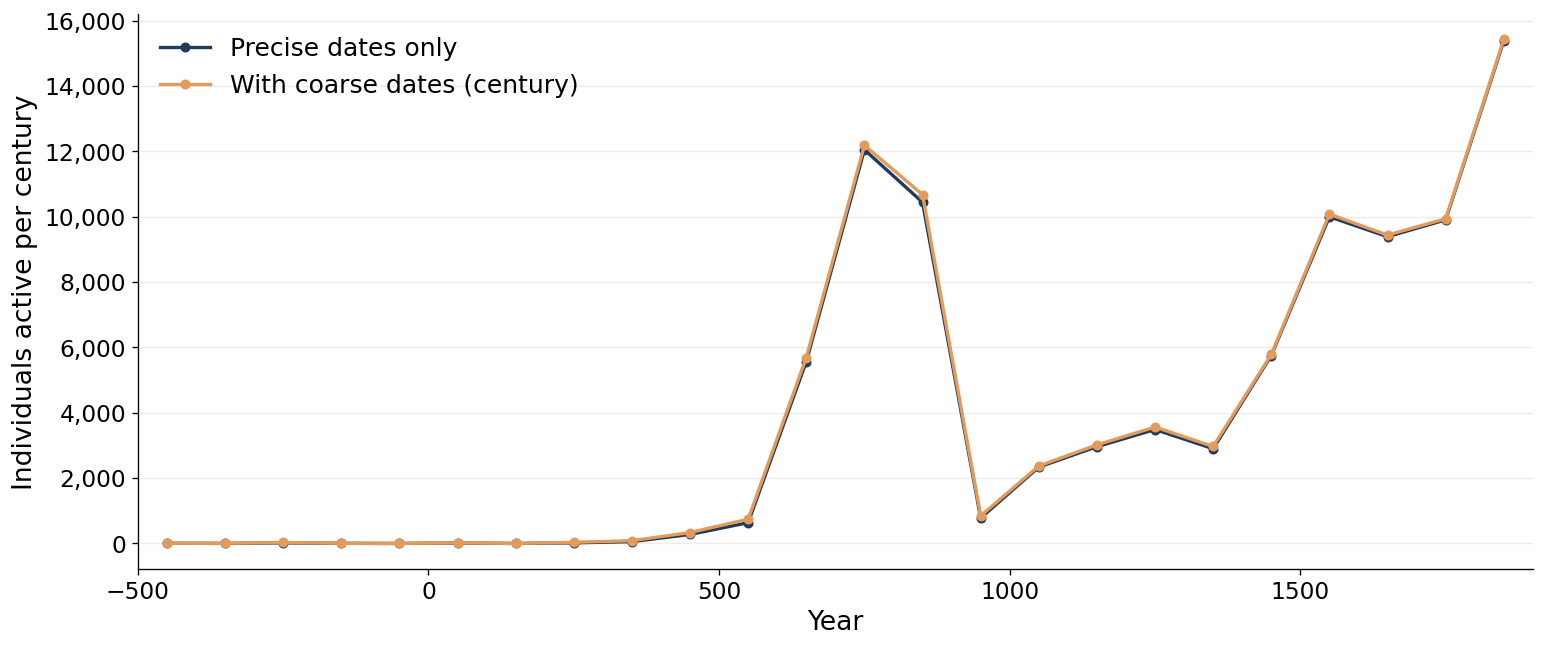

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for column, color in COARSE_COLORS.items():
    ax.plot(per_century['period'] + 50, per_century[column], color=color, marker='o', markersize=5, label=column)
ax.set_xlim(FIRST_YEAR, LAST_YEAR)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Year')
ax.set_ylabel('Individuals active per century')
ax.grid(axis='y')
ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
plt.show()

### Figure 2: Individuals born, active and in late life per decade

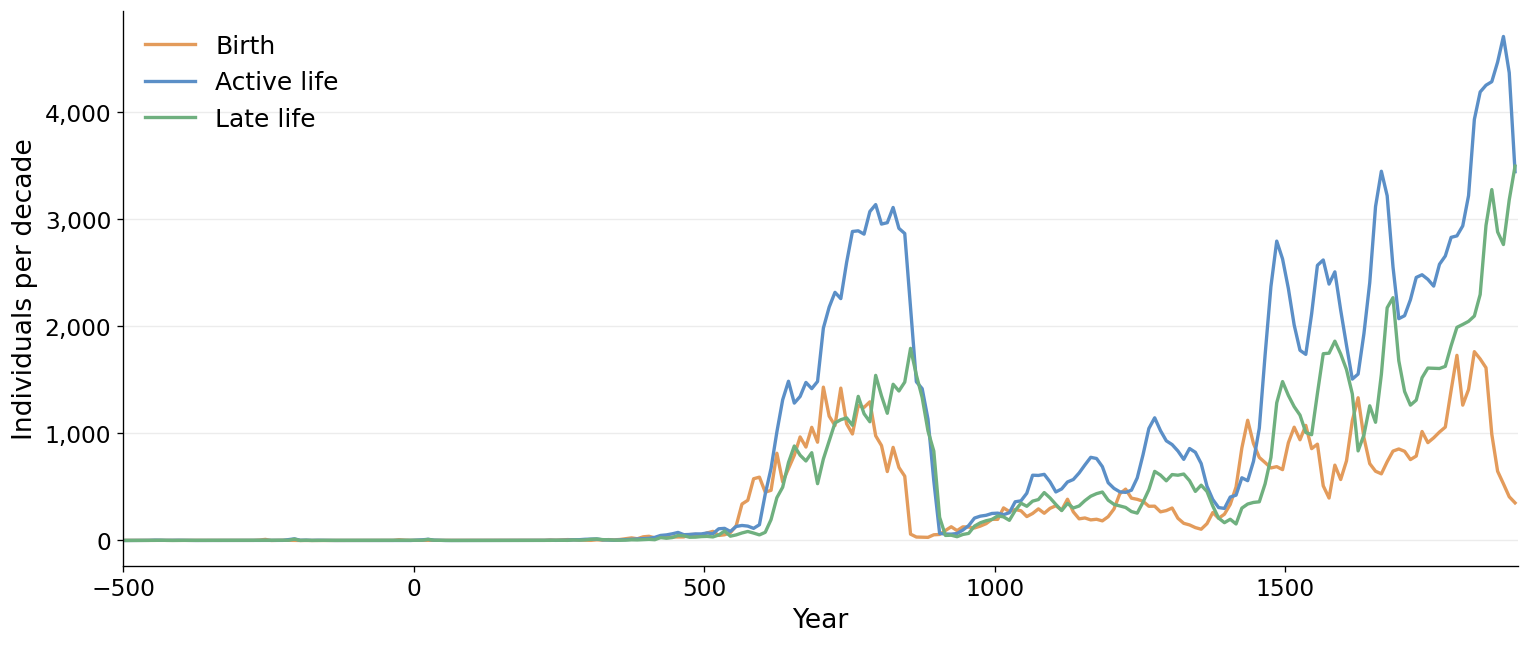

In [11]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for column, color in STAGE_COLORS.items():
    ax.plot(per_decade['period'] + 5, per_decade[column], color=color, label=column)
ax.set_xlim(FIRST_YEAR, LAST_YEAR)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Year')
ax.set_ylabel('Individuals per decade')
ax.grid(axis='y')
ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
plt.show()

### Figure 3: Individuals in early, active and late life per decade

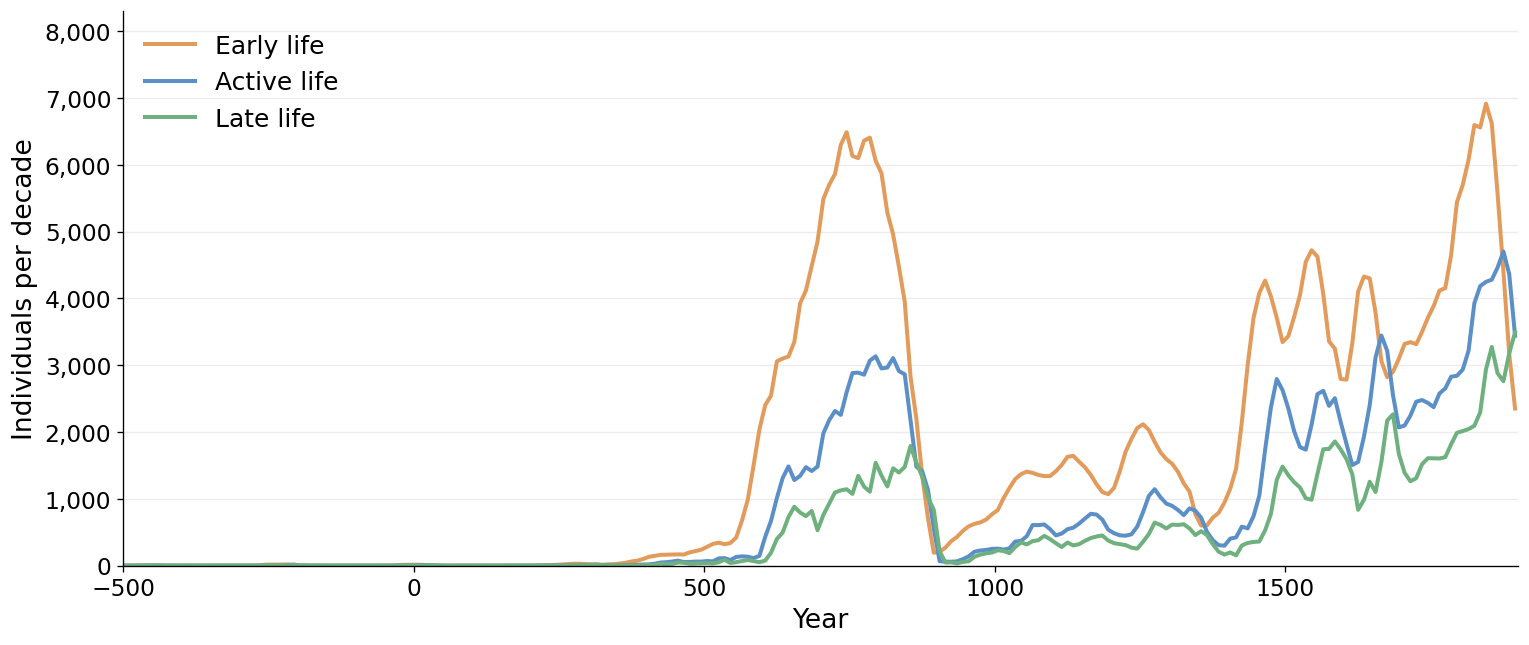

In [12]:
def plot_stages(frame, xlim, golden_age=None, title=None):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    if golden_age:
        label, first, last = golden_age
        ax.axvspan(first, last, color=PALE_GREY, zorder=0)
        ax.text((first + last) / 2, frame[list(LIFE_STAGE_COLORS)].max().max_horizontal().item() * 1.08, label,
                ha='center', va='bottom', fontsize=SMALL_LEGEND_FONTSIZE + 2, color=MUTED_TEXT)
    for column, color in LIFE_STAGE_COLORS.items():
        ax.plot(frame['period'] + 5, frame[column], color=color, linewidth=2.4, label=column)
    if title:
        fig.suptitle(title, fontsize=POLITY_TITLE_FONTSIZE, color='black')
    top = frame[list(LIFE_STAGE_COLORS)].max().max_horizontal().item()
    ax.set_ylim(0, top * 1.2)
    ax.set_xlim(*xlim)
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xlabel('Year')
    ax.set_ylabel('Individuals per decade')
    ax.grid(axis='y')
    ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
    plt.show()


plot_stages(per_stage, (FIRST_YEAR, LAST_YEAR))

### Figure 4: Lives of the most-linked Chinese individuals, 500–1200

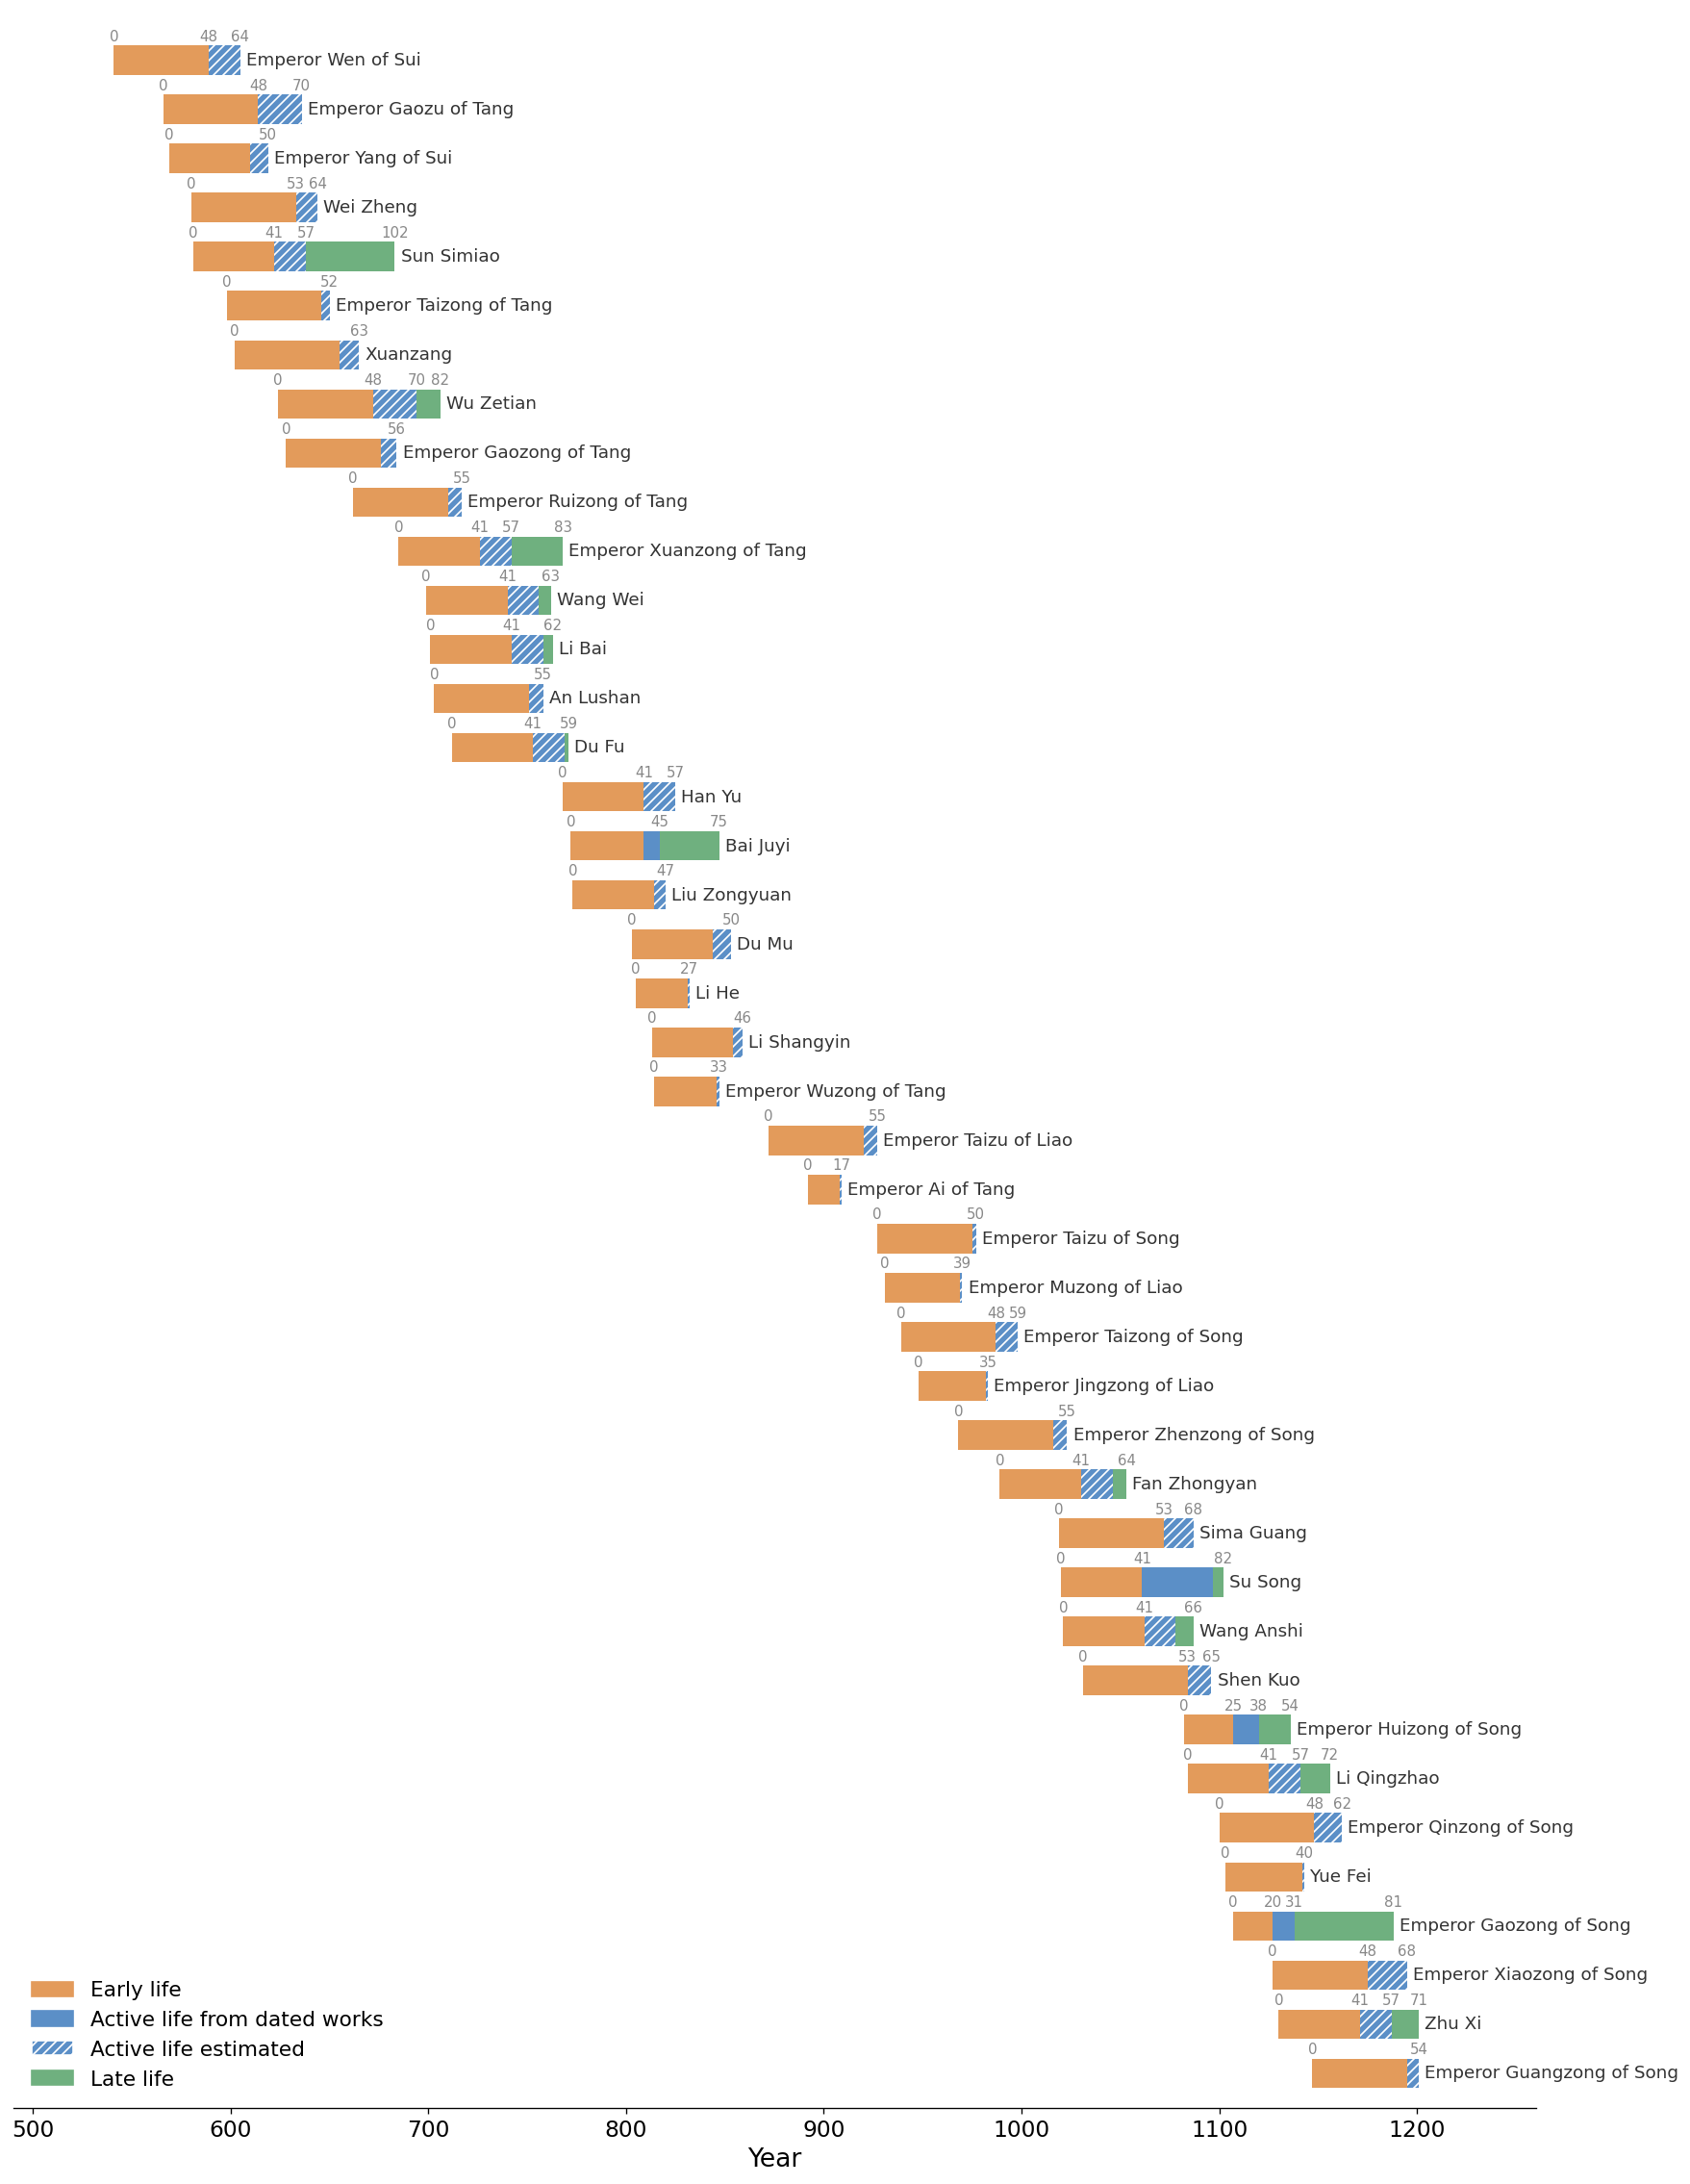

In [13]:
fig, ax = plt.subplots(figsize=(15, 0.42 * lifespans.height + 1.5))
for row, person in enumerate(lifespans.iter_rows(named=True)):
    segments = [
        (person['birth_year'], person['active_life_start'], LIFE_STAGE_COLORS['Early life']),
        (person['active_life_start'], person['active_life_end'] + 1, LIFE_STAGE_COLORS['Active life']),
        (person['active_life_end'] + 1, person['death_year'] + 1, LIFE_STAGE_COLORS['Late life']),
    ]
    for start, end, color in segments:
        if end > start:
            estimated = color == LIFE_STAGE_COLORS['Active life'] and person['active_life_source'] == 'estimated'
            ax.barh(row, end - start, left=start, height=0.6, color=color, hatch='////' if estimated else None, edgecolor='white', linewidth=0)
    steps = [person['birth_year'], person['active_life_start'], person['active_life_end'] + 1, person['death_year'] + 1]
    shown = [year for i, year in enumerate(steps) if i == len(steps) - 1 or steps[i + 1] - year >= AGE_LABEL_GAP]
    for year in shown:
        ax.text(year, row + 0.34, year - person['birth_year'], ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)
    ax.text(person['death_year'] + 4, row, person['name'], va='center', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
ax.legend(handles=[
    Patch(color=LIFE_STAGE_COLORS['Early life'], label='Early life'),
    Patch(color=LIFE_STAGE_COLORS['Active life'], label='Active life from dated works'),
    Patch(facecolor=LIFE_STAGE_COLORS['Active life'], hatch='////', edgecolor='white', label='Active life estimated'),
    Patch(color=LIFE_STAGE_COLORS['Late life'], label='Late life'),
], loc='lower left', fontsize=LEGEND_FONTSIZE - 2)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(-0.7, lifespans.height)
ax.set_xlim(lifespan_first - 10, lifespan_last + 60)
ax.set_xlabel('Year')
plt.tight_layout()
plt.show()